# Delta wave detection

Run this notebook from top to bottom in a Python kernel with `neuro_py` installed.
The synthetic example runs without external data and demonstrates detection,
waveform plots, interval restrictions, and a CellExplorer MAT-file round trip.
The optional session section uses HMC1/day8 after you set `RUN_SESSION = True`.

The detector returns a pandas DataFrame. Its default save name is
**`basename.deltaWaves.events.mat`**, and `event_name` allows custom names.
Existing files are always protected. Session saving is disabled in this notebook
until you explicitly enable it; the export demonstration uses a temporary folder.

In [1]:
%matplotlib inline

from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from neuro_py.detectors import detect_delta_waves, save_delta_wave_events
from neuro_py.io import loading
from neuro_py.io.matlab import load_mat

## 1. Create a reproducible single-channel recording

The sample clock is in seconds, the sampling rate is in Hz, and LFP shape is
`(n_samples,)`. Three isolated positive waves are embedded in low-amplitude noise.

In [2]:
fs = 250.0
sample_times = np.arange(0, 30, 1 / fs)
rng = np.random.default_rng(42)
trace = rng.normal(0, 0.1, sample_times.size)
expected_peaks = np.array([5.0, 15.0, 25.0])
for peak in expected_peaks:
    relative_time = sample_times - peak
    trace += (
        8
        * np.cos(2 * np.pi * 2.5 * relative_time)
        * np.exp(-((relative_time / 0.15) ** 2))
    )

## 2. Detect waves and inspect the DataFrame

For array input, disable session-based NREM/EMG restrictions explicitly and set
`save_mat=False`. Artifact rejection is disabled for this known-clean simulation:
its deliberately rare, large waves exceed the raw-amplitude artifact threshold.
The real-session example keeps artifact rejection enabled.

In [3]:
array_options = dict(
    lfp=trace,
    fs=fs,
    timestamps=sample_times,
    nrem_restrict=False,
    emg_threshold=np.inf,
    reject_artifacts=False,
)
events = detect_delta_waves(**array_options, save_mat=False)
display(events[["start", "peaks", "stop", "duration", "amplitude", "amplitudeUnits"]])
np.testing.assert_allclose(events.peaks, expected_peaks, atol=0.02)
assert events.duration.between(0.15, 0.65).all()
print(f"Detected {len(events)} waves; all simulated peaks recovered within 20 ms.")

,start,peaks,stop,duration,amplitude,amplitudeUnits
0,4.844,4.996,5.152,0.308,12.853640,zscore
1,14.840,14.996,15.152,0.312,12.809630,zscore
2,24.844,24.996,25.152,0.308,12.841885,zscore


Detected 3 waves; all simulated peaks recovered within 20 ms.


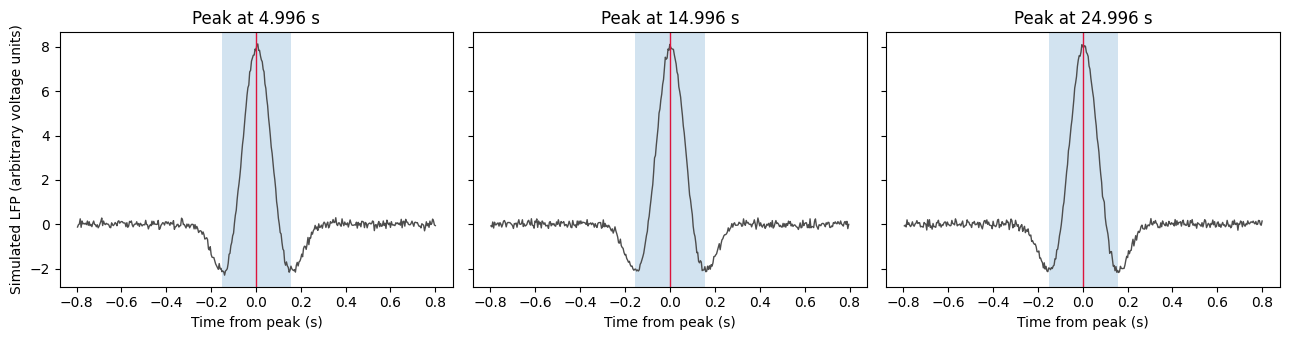

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, event in zip(axes, events.itertuples()):
    window = np.abs(sample_times - event.peaks) < 0.8
    ax.plot(sample_times[window] - event.peaks, trace[window], color="0.3", lw=1)
    ax.axvspan(event.start - event.peaks, event.stop - event.peaks, alpha=0.2)
    ax.axvline(0, color="crimson", lw=1)
    ax.set(title=f"Peak at {event.peaks:.3f} s", xlabel="Time from peak (s)")
axes[0].set_ylabel("Simulated LFP (arbitrary voltage units)")
fig.tight_layout()
plt.show()

## 3. Restrict detection and exclude an interval

`detection_epochs` and `ignore_intervals` accept `(n_intervals, 2)` arrays in
seconds or `nelpy.EpochArray` objects. The following example keeps the first and
last recording windows, then excludes the last wave. Excluded samples and
recording gaps are never bridged by a detected event.

In [5]:
restricted = detect_delta_waves(
    **array_options,
    detection_epochs=[[2, 8], [22, 28]],
    ignore_intervals=[[24.9, 25.1]],
    save_mat=False,
)
display(restricted[["start", "peaks", "stop", "amplitude"]])
np.testing.assert_allclose(restricted.peaks, [5.0], atol=0.02)
display(restricted.attrs["detectorinfo"]["detectionintervals"])

,start,peaks,stop,amplitude
0,4.844,4.996,5.152,12.87939


array([[ 3.   ,  7.   ],
       [23.   , 23.896],
       [26.1  , 27.   ]])

## 4. Event fields and metadata


Each row contains `start`, `stop`, `timestamps`, `peaks`, `amplitude`,
`amplitudeUnits`, `values`, `eventID`, `eventIDlabels`, `eventIDbinary`, `center`,
and `duration`. Times are seconds; amplitude is the peak-to-final-trough
difference in z units. The `values` tuple holds standardized initial trough,
peak, and final trough values, also exposed as `start_value`, `peak_value`, and
`stop_value` columns. All events have ID 1 and label `delta`.

Shared metadata lives in `events.attrs["detectorinfo"]`, including the usable
detection intervals, parameters, effective amplitude threshold, UTC detection
date, and detection channel in both indexing conventions. The saved MATLAB
struct follows the [CellExplorer events format](https://cellexplorer.org/datastructure/data-structure-and-format/#events),
including `(n_events, 2)` timestamps, column vectors for event measurements, and
an `(n_events, 3)` values array. Zero-event and one-event exports preserve these shapes.

In [6]:
display(events.head())
display(events.attrs["detectorinfo"])

,start,stop,peaks,amplitude,center,duration,start_value,peak_value,stop_value,timestamps,values,amplitudeUnits,eventID,eventIDlabels,eventIDbinary
0,4.844,5.152,4.996,12.853640,4.998,0.308,-3.305979,9.579129,-3.274511,"(4.844, 5.152)","(-3.305978559103807, 9.579129400871768, -3.274...",zscore,1,delta,False
1,14.840,15.152,14.996,12.809630,14.996,0.312,-3.237116,9.550003,-3.259627,"(14.84, 15.152000000000001)","(-3.2371155476478566, 9.550003020049784, -3.25...",zscore,1,delta,False
2,24.844,25.152,24.996,12.841885,24.998,0.308,-3.217037,9.587129,-3.254756,"(24.844, 25.152)","(-3.2170372924046604, 9.587129134656228, -3.25...",zscore,1,delta,False


{'detectorname': 'neuro_py.detectors.detect_delta_waves',
 'detectiondate': '2026-10-14T23:14:44.670880+00:00',
 'detectionintervals': array([[ 1.   , 28.996]]),
 'detectionparms': {'channel': [],
  'threshold': 3.0,
  'thresholds': (1.0, 3.0, 0.0, 1.5),
  'durations': (0.15, 0.65),
  'filter_band': (0.5, 9.0),
  'passband': (1.0, 6.0),
  'fs': 250.0,
  'nrem_restrict': False,
  'emg_threshold': inf,
  'reject_artifacts': False,
  'edge_buffer': 1.0,
  'brain_regions': ['PFC', 'MEC', 'LEC', 'EC', 'ILA', 'PL', 'Cortex', 'CTX'],
  'verify_firing': False,
  'firing_verified': False,
  'ignore_intervals': array([], shape=(0, 2), dtype=float64)},
 'detectionchannel': [],
 'detectionchannel1': [],
 'threshold': 3.0}

## 5. Save the default filename, customize it, and verify overwrite protection

This cell runs in a new temporary session directory each time. It exercises the
detector's default saving behavior, reads back the CellExplorer struct, and saves
a custom event name. The temporary files are removed when the cell completes.
For a real session, the same defaults produce `basename.deltaWaves.events.mat`.

In [7]:
with TemporaryDirectory(prefix="neuro_py_delta_tutorial_") as temporary:
    demo_basepath = Path(temporary) / "demo"
    demo_basepath.mkdir()

    # save_mat=True and event_name="deltaWaves" are the detector defaults.
    saved_events = detect_delta_waves(basepath=demo_basepath, **array_options)
    default_path = Path(saved_events.attrs["event_file"])
    assert default_path.name == "demo.deltaWaves.events.mat"
    saved = load_mat(default_path)["deltaWaves"]
    np.testing.assert_allclose(saved["timestamps"], events[["start", "stop"]])
    np.testing.assert_allclose(np.asarray(saved["peaks"]).ravel(), events.peaks)
    print(f"Default filename: {default_path.name}")

    custom_path = Path(
        save_delta_wave_events(events, demo_basepath, event_name="myDeltaWaves")
    )
    assert custom_path.name == "demo.myDeltaWaves.events.mat"
    print(f"Custom filename: {custom_path.name}")

    original_bytes = default_path.read_bytes()
    try:
        save_delta_wave_events(events, demo_basepath)
    except FileExistsError:
        print("Existing event file protected: FileExistsError raised as expected.")
    else:
        raise AssertionError("An existing event file should never be replaced.")
    assert default_path.read_bytes() == original_bytes

Default filename: demo.deltaWaves.events.mat
Custom filename: demo.myDeltaWaves.events.mat
Existing event file protected: FileExistsError raised as expected.


## 6. Optional: run on a CellExplorer session

Set `RUN_SESSION=True` and edit `basepath` if needed. The default session workflow
uses the `Delta` channel tag, or selects the channel with the greatest relative
1–6 Hz power among matching cortical regions. Channels tagged `Bad` are excluded.
Public `channel` arguments use **zero-based** indexing; MATLAB metadata is
converted automatically (`channel=53` is MATLAB channel 54).

The session needs `.session.mat`, `.lfp` (or `.eeg`), `.SleepState.states.mat`,
and `.EMGFromLFP.LFP.mat`. Detection is restricted to NREM and EMG below 0.6 for
at least one second. Set `nrem_restrict=False` and/or `emg_threshold=np.inf` to
disable a restriction explicitly. This run keeps the default artifact rejection.

Session detection below uses `save_mat=False` so it can be rerun safely. A separate
export cell is controlled by `SAVE_SESSION_EVENTS`. Its event name defaults to
`deltaWaves`; choose a custom name to keep an existing detection alongside it.

In [8]:
RUN_SESSION = True
basepath = Path(r"S:\data\HMC\HMC1\day8")
SAVE_SESSION_EVENTS = False
session_event_name = "deltaWaves_test"

session_events = None
if RUN_SESSION:
    session_events = detect_delta_waves(basepath, save_mat=False)
    print(f"Detected {len(session_events)} delta waves in {basepath.name}.")
    display(session_events[["start", "peaks", "stop", "duration", "amplitude"]].head())
    display(session_events.attrs["detectorinfo"])
else:
    print("Session example skipped. Set RUN_SESSION=True to execute it.")

Detected 4268 delta waves in day8.


,start,peaks,stop,duration,amplitude
0,147.3288,147.4352,147.5608,0.2320,4.573611
1,239.1672,239.2984,239.4808,0.3136,6.354530
2,243.8168,243.9720,244.1208,0.3040,3.573012
3,248.2280,248.3384,248.5232,0.2952,4.578029
4,253.4328,253.5608,253.7760,0.3432,3.790883


{'detectorname': 'neuro_py.detectors.detect_delta_waves',
 'detectiondate': '2026-10-14T23:14:54.677299+00:00',
 'detectionintervals': array([[   75.    ,    86.    ],
        [  119.    ,   184.    ],
        [  212.    ,   256.    ],
        [  307.    ,   317.    ],
        [  332.    ,   353.    ],
        [  373.    ,   395.    ],
        [  426.    ,   461.    ],
        [  675.    ,   701.    ],
        [  738.    ,   754.    ],
        [  776.    ,   782.    ],
        [  889.    ,   895.    ],
        [  934.    ,   953.    ],
        [ 1014.    ,  1044.    ],
        [ 1108.    ,  1140.    ],
        [ 1347.    ,  1414.    ],
        [ 1438.    ,  1451.    ],
        [ 1465.    ,  1477.    ],
        [ 3199.    ,  3211.    ],
        [ 3267.    ,  3275.    ],
        [ 3308.    ,  3318.    ],
        [ 3339.    ,  3363.    ],
        [ 3442.    ,  3454.    ],
        [ 3635.    ,  3640.    ],
        [ 4792.    ,  4794.6512],
        [ 4835.172 ,  4837.    ],
        [ 5162. 

Plot the first session wave using a short slice of the memory-mapped recording.
The full multichannel LFP is not copied into memory. If no waves were detected,
the plot is skipped.

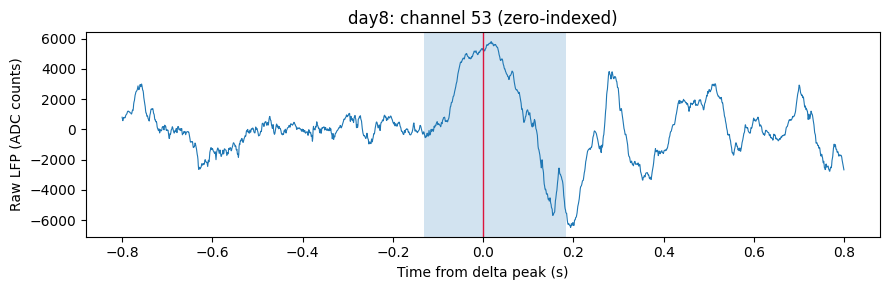

In [11]:
if RUN_SESSION and session_events is not None and not session_events.empty:
    info = session_events.attrs["detectorinfo"]
    session_fs = info["detectionparms"]["fs"]
    channel = int(info["detectionchannel"])
    metadata = load_mat(basepath / f"{basepath.name}.session.mat")["session"]
    loaded = loading.loadLFP(
        str(basepath),
        n_channels=int(metadata["extracellular"]["nChannels"]),
        frequency=session_fs,
    )
    if loaded is None:
        raise FileNotFoundError(f"No LFP recording found in {basepath}.")
    session_lfp, session_times = loaded
    event = session_events.iloc[1]
    left, right = np.searchsorted(session_times, [event.peaks - 0.8, event.peaks + 0.8])
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(
        session_times[left:right] - event.peaks,
        session_lfp[left:right, channel],
        lw=0.8,
    )
    ax.axvspan(event.start - event.peaks, event.stop - event.peaks, alpha=0.2)
    ax.axvline(0, color="crimson", lw=1)
    ax.set(
        xlabel="Time from delta peak (s)",
        ylabel="Raw LFP (ADC counts)",
        title=f"{basepath.name}: channel {channel} (zero-indexed)",
    )
    fig.tight_layout()
    plt.show()
    del session_lfp, session_times, loaded

In [10]:
if SAVE_SESSION_EVENTS:
    if session_events is None:
        raise ValueError("Run the session detection cell before saving its events.")
    destination = basepath / f"{basepath.name}.{session_event_name}.events.mat"
    if destination.exists():
        print(
            f"Kept existing file: {destination}. Choose a different session_event_name to save another run."
        )
    else:
        filename = save_delta_wave_events(
            session_events, basepath, event_name=session_event_name
        )
        print(f"Saved {filename}")
else:
    print(
        "Session export disabled. Set SAVE_SESSION_EVENTS=True to save a reviewed detection."
    )

Session export disabled. Set SAVE_SESSION_EVENTS=True to save a reviewed detection.


## Algorithm and differences from neurocode


The morphology detector follows `FindDeltaWaves.m`: subtract a fifth-order
0.5 Hz Chebyshev-II lowpass from the raw LFP, lowpass at 9 Hz, differentiate,
and lowpass the derivative at 9 Hz using order eight. Both filtering stages
use forward/backward filtering with 20 dB stopband attenuation. Upward/downward/
upward derivative zero crossings identify the initial trough, positive peak,
and final trough. Wave amplitudes use sample standard deviations pooled across
the usable segments. The initial trough must be below the peak, and waves must
last 150–650 ms. Acceptance requires either a peak above 3 SD with a nonpositive
final trough, or a peak at least 1 SD with a final trough below -1.5 SD. The
peak-to-final-trough difference must also exceed `threshold=3`.

`filter_band` controls morphology filtering; `passband` controls channel selection
only. This distinction reflects what the MATLAB code actually does.

The Python implementation uses stable second-order sections at the native
sampling rate. It filters each contiguous usable segment separately, excludes
NaNs and artifacts instead of interpolating over them, and rejects events within
`edge_buffer=1` second of segment boundaries. Artifacts use the MATLAB wrapper's
6 SD amplitude and 10 SD difference criteria, with 0.5 s and 0.1 s padding.
The difference threshold is in SD units of the raw signal, as in `CleanLFP.m`.
These choices prevent events across gaps but can exclude waves retained by MATLAB.
The Python sample clock starts at zero, consistent with other neuro_py loaders;
the MATLAB wrapper starts at `1/fs`.

Firing verification defaults to `False`, following the wrapper's documented
default (its executable default is `True`). Enable `verify_firing=True` to raise
the amplitude cutoff based on cortical population firing suppression, optionally
supplying `spike_times` as one seconds-based array per unit. Otherwise cortical
spikes are loaded through `loading.load_spikes`. This heuristic uses 10 ms bins
over ±0.5 s, Gaussian smoothing with sigma one bin, per-event z scores averaged
over ±50 ms, and a moving mean over up to 100 amplitude-ordered events. It uses
the lowest amplitude cutoff with mean suppression ≤-0.5 and never lowers the
requested amplitude threshold. Missing spikes or absent suppression produce a
warning and retain the LFP detections; metadata records verification as unsuccessful.
No interactive debugger or channel picker runs.